# Telco Customer Churn Prediction

### Context

"Predict behavior to retain customers. You can analyze all relevant customer data and develop focused customer retention programs." [IBM Sample Data Sets]

### Content

Each row represents a customer, each column contains customer’s attributes described on the column Metadata.

The data set includes information about:
- **Customers who left within the last month** – the column is called `Churn`
- **Services that each customer has signed up for** – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
- **Customer account information** – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
- **Demographic info about customers** – gender, age range, and if they have partners and dependents

## 1. Data Loading & Initial Exploration

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Show all columns in the DataFrame
pd.set_option('display.max_columns', None)

In [2]:
# Load RAW data
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


- based on the .describe (and exploration) we can see that most categorical variables have between 2, 3, or 4 categories
- So for those that only have 2 (binary) let's just replace by 0 and 1
- For those that have 3 or 4 we can do One-Hot encoding

## Binary Encoding

In [4]:
# Binary categorical columns (2 unique values)
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
#Map Yes/No and Male/Female to 0/1
df[binary_cols] = df[binary_cols].replace({
    'Yes': 1, 'No': 0,
    'Male': 1, 'Female': 0
}).astype(int)

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,3668-QPYBK,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


## One-Hot encoding

In [6]:
# Categorical columns with more than 2 values
multi_cat_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
]
# One-hot encode
df = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True)

In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,0,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.5,0,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,0,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


## Cleaning

In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [9]:
df = df.drop('customerID', axis=1)

In [10]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int) # converts True/False to 1/0 for all boolean cols

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7032 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  MultipleLines_Y

In [12]:
corr_matrix = df.corr(numeric_only=True)
churn_corr = corr_matrix['Churn'].sort_values(ascending=False)
print(churn_corr)

Churn                                    1.000000
InternetService_Fiber optic              0.308020
PaymentMethod_Electronic check           0.301919
MonthlyCharges                           0.193356
PaperlessBilling                         0.191825
SeniorCitizen                            0.150889
StreamingTV_Yes                          0.063228
StreamingMovies_Yes                      0.061382
MultipleLines_Yes                        0.040102
PhoneService                             0.011942
gender                                  -0.008612
MultipleLines_No phone service          -0.011942
DeviceProtection_Yes                    -0.066160
OnlineBackup_Yes                        -0.082255
PaymentMethod_Mailed check              -0.091683
PaymentMethod_Credit card (automatic)   -0.134302
Partner                                 -0.150448
Dependents                              -0.164221
TechSupport_Yes                         -0.164674
OnlineSecurity_Yes                      -0.171226


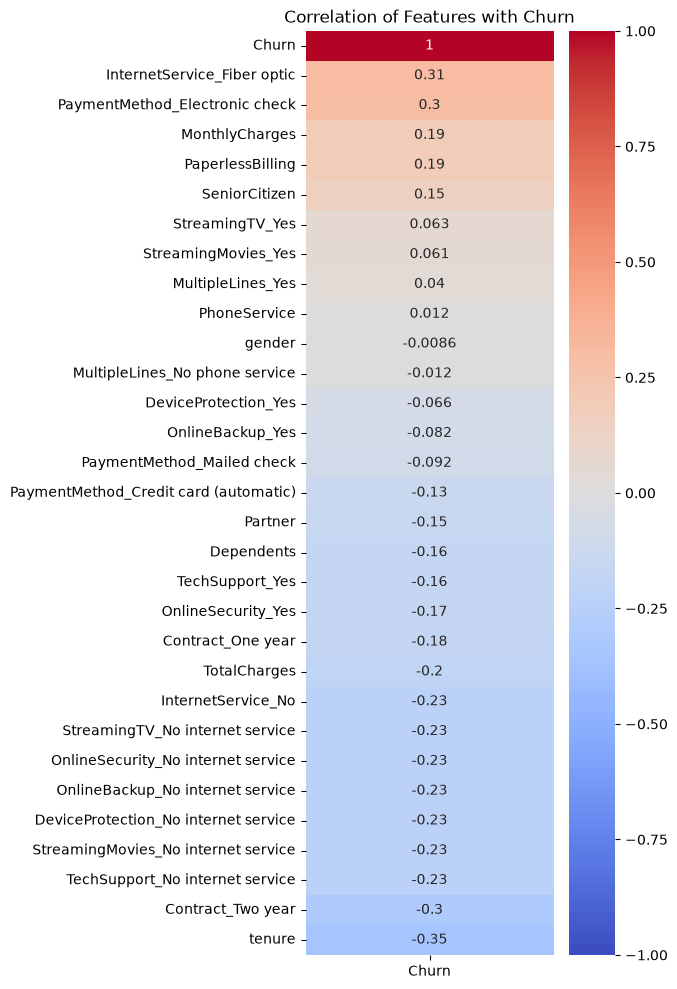

In [13]:
# Compute correlation matrix only for numeric columns
corr_matrix = df.corr(numeric_only=True)

# Focus on correlation with Churn
churn_corr = corr_matrix[['Churn']].sort_values(by='Churn', ascending=False)

# Plot heatmap
plt.figure(figsize=(4, 12))
sns.heatmap(churn_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Features with Churn')
plt.show()

Negative (lower value → less likely to churn):

- tenure (-0.35) → Customers who stay longer are less likely to churn.
- Contract_Two year (-0.30) → Customers on long-term contracts churn much less.
- Contract_One year (-0.18) → Same trend but weaker than two-year contracts.

Positive (higher value → more likely to churn):

 - InternetService_Fiber optic (+0.31) → Fiber optic users churn more in this dataset.
 - PaymentMethod_Electronic check (+0.30) → Customers paying electronically via check churn more.

## Look for multicolinearity (VIF)

In [14]:
# We need to collapse redundant columns before running VIF
df['No_internet_service'] = (
    df['OnlineSecurity_No internet service'] |
    df['OnlineBackup_No internet service'] |
    df['DeviceProtection_No internet service'] |
    df['TechSupport_No internet service'] |
    df['StreamingTV_No internet service'] |
    df['StreamingMovies_No internet service']
).astype(int)

# Drop the original redundant dummies
drop_cols = [col for col in df.columns if 'No internet service' in col]
df = df.drop(columns=drop_cols)

# Handle PhoneService redundancy
if 'MultipleLines_No phone service' in df.columns:
    df['No_phone_service'] = df['MultipleLines_No phone service'].astype(int)
    df = df.drop(columns=['MultipleLines_No phone service'])

In [15]:
# Prepare X
X = df.drop(columns=['Churn'])
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

In [16]:
# Run VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# Remove rows with missing or infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by='VIF', ascending=False)

print(vif_data)

C:\Users\admin\AppData\Local\Temp\ipykernel_9076\3055109083.py:12: UserWarning: The design matrix is poorly conditioned (condition number=6.91e+15). VIF calculations may be numerically unstable.
  vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
c:\Users\admin\Desktop\Telco Customer Churn ML\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\admin\Desktop\Telco Customer Churn ML\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\admin\Desktop\Telco Customer Churn ML\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The mod

                                  feature           VIF
5                            PhoneService  1.000800e+15
23                    No_internet_service  1.000800e+15
24                       No_phone_service  1.000800e+15
11                     InternetService_No  1.000800e+15
7                          MonthlyCharges  8.660896e+02
10            InternetService_Fiber optic  1.485008e+02
17                    StreamingMovies_Yes  2.415639e+01
16                        StreamingTV_Yes  2.408002e+01
8                            TotalCharges  1.081149e+01
4                                  tenure  7.584453e+00
9                       MultipleLines_Yes  7.289761e+00
14                   DeviceProtection_Yes  6.924754e+00
13                       OnlineBackup_Yes  6.796678e+00
15                        TechSupport_Yes  6.476508e+00
12                     OnlineSecurity_Yes  6.338349e+00
19                      Contract_Two year  2.652328e+00
21         PaymentMethod_Electronic check  1.976

c:\Users\admin\Desktop\Telco Customer Churn ML\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\admin\Desktop\Telco Customer Churn ML\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


 - Clearly we can see there's multicolinearity between features
 - So either we need to drop some features or use regularization techniques like Lasso or Ridge regression to handle this
 - Or use tree based models which are less sensitive to multicollinearity
 - In decision trees, splits are based on feature importance for reducing impurity — redundant features just compete, but won’t cause unstable predictions.

## Production Pipeline Preparation

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load RAW data so the pipeline learns to process it from scratch
raw_df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# The only manual fix needed before splitting: converting TotalCharges to numeric
raw_df['TotalCharges'] = pd.to_numeric(raw_df['TotalCharges'], errors='coerce')

# 2. Separate target from features
X = raw_df.drop(columns=['Churn', 'customerID'])
y = raw_df['Churn'].map({'Yes': 1, 'No': 0})

# 3. Train-test split with stratification to handle class imbalance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Calculate scale_pos_weight for imbalanced models
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 4. Define feature types
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X_train.columns if col not in numeric_features]

# 5. Build preprocessing pipelines
# Numeric: Impute missing values with median, then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical: Impute missing with most frequent, then One-Hot Encode
# handle_unknown='ignore' prevents API crashes if new categories appear in production
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into a single preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

## Baseline Model Selection
Before hyperparameter tuning, let's establish a baseline. We will evaluate three tree-based algorithms to see which one handles our imbalanced data best out-of-the-box. 
The primary metric is **Recall** (to catch as many churners as possible).

In [18]:
import time
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# Filter scikit-learn deprecation/convergence noise for clean notebook output
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Target threshold for high recall on churners
THRESHOLD = 0.3

# Initialize all 5 baseline models 
models = {
    "Logistic Regression (L1/Lasso)": LogisticRegression(
        solver='saga', l1_ratio=1.0, penalty='elasticnet',
        class_weight='balanced', random_state=42, max_iter=2000
    ),
    "Logistic Regression (L2/Ridge)": LogisticRegression(
        solver='lbfgs', penalty='l2',
        class_weight='balanced', random_state=42, max_iter=1000
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=500, learning_rate=0.05, class_weight='balanced',
        random_state=42, n_jobs=-1, verbose=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
        random_state=42, n_jobs=-1, eval_metric='logloss'
    )
}

print(f"Total models to evaluate: {len(models)}\n")

for idx, (name, model) in enumerate(models.items(), 1):
    print(f"[{idx}/5] ================ {name} ================")
    
    # Bundle preprocessor and classifier
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train
    start_train = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - start_train
    
    # Predict probabilities and apply threshold
    start_pred = time.time()
    proba = pipeline.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)
    pred_time = time.time() - start_pred
    
    print(f"⏱ Training time: {train_time:.2f} s | ⏱ Inference time: {pred_time:.4f} s")
    print(classification_report(y_test, y_pred, digits=3))
    print("-" * 55)

Total models to evaluate: 5

[1/5] ================ Logistic Regression (L1/Lasso) ================
⏱ Training time: 0.80 s | ⏱ Inference time: 0.0460 s
              precision    recall  f1-score   support

           0      0.955     0.558     0.705      1035
           1      0.432     0.928     0.589       374

    accuracy                          0.656      1409
   macro avg      0.693     0.743     0.647      1409
weighted avg      0.816     0.656     0.674      1409

-------------------------------------------------------
[2/5] ================ Logistic Regression (L2/Ridge) ================
⏱ Training time: 0.31 s | ⏱ Inference time: 0.0320 s
              precision    recall  f1-score   support

           0      0.955     0.555     0.702      1035
           1      0.429     0.928     0.587       374

    accuracy                          0.654      1409
   macro avg      0.692     0.741     0.644      1409
weighted avg      0.816     0.654     0.671      1409

-------------

In [19]:
# Threshold tuning comparison between XGBoost and Logistic Regression (L1)
from sklearn.metrics import recall_score, precision_score
from sklearn.pipeline import Pipeline

print("=" * 60)
print("Threshold Sensitivity Analysis")
print("=" * 60)

# 1. Get probabilities for both top candidates
# Retrain best linear pipeline for explicit comparison
l1_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', models["Logistic Regression (L1/Lasso)"])
])
l1_pipeline.fit(X_train, y_train)

xgb_proba = proba  # already predicted for XGBoost in the previous cell
l1_proba = l1_pipeline.predict_proba(X_test)[:, 1]

print(f"{'Thresh':<8} | {'XGB Rec':<9} {'XGB Prec':<9} | {'L1 Rec':<9} {'L1 Prec':<9}")
print("-" * 55)

for thresh in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    xgb_preds = (xgb_proba >= thresh).astype(int)
    l1_preds = (l1_proba >= thresh).astype(int)
    
    xgb_rec = recall_score(y_test, xgb_preds, pos_label=1)
    xgb_prec = precision_score(y_test, xgb_preds, pos_label=1)
    
    l1_rec = recall_score(y_test, l1_preds, pos_label=1)
    l1_prec = precision_score(y_test, l1_preds, pos_label=1)
    
    print(f"{thresh:<8.2f} | {xgb_rec:<9.3f} {xgb_prec:<9.3f} | {l1_rec:<9.3f} {l1_prec:<9.3f}")

Threshold Sensitivity Analysis
Thresh   | XGB Rec   XGB Prec  | L1 Rec    L1 Prec  
-------------------------------------------------------
0.20     | 0.858     0.450     | 0.963     0.388    
0.25     | 0.832     0.466     | 0.939     0.407    
0.30     | 0.802     0.482     | 0.928     0.432    
0.35     | 0.773     0.493     | 0.906     0.447    
0.40     | 0.746     0.515     | 0.866     0.466    
0.45     | 0.709     0.521     | 0.837     0.483    
0.50     | 0.690     0.540     | 0.786     0.503    


### Model Selection & Tuning Rationale

- **Baseline Observation**: Regularized Logistic Regression (L1/Lasso) achieves an impressive Recall of `0.928` at threshold `0.30`, showing that feature shrinkage handles collinear one-hot features effectively.
- **Goal for XGBoost**: An untuned XGBoost baseline achieves `0.802` Recall. However, gradient boosting can capture non-linear relationships and interactions that linear models miss.
- **Optuna Strategy**: We run 30 trials with 3-fold Stratified Cross-Validation directly optimizing for **Recall at threshold 0.30**. We tune structural depth (`max_depth: 3-8`) alongside strong regularization (`gamma`, `reg_alpha`, `reg_lambda`) to prevent memorization and push Recall toward the >0.90 level.

## Hyperparameter Tuning with Optuna
We use Optuna to search for the best hyperparameter configuration for XGBoost. 
We evaluate each trial across a 3-fold Stratified Cross-Validation using our custom threshold (`0.3`) to directly optimize for **Recall** on churners.

In [20]:
import optuna
import numpy as np
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score

# Optimize directly for the chosen business threshold
THRESHOLD = 0.3

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 750),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.5, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.5, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 6.0),
        "scale_pos_weight": scale_pos_weight,
        "random_state": 42,
        "n_jobs": -1,
        "eval_metric": "logloss"
    }
    
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    fold_recalls = []
    
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        
        # Preprocessor fits inside fold to prevent leakage
        fold_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', XGBClassifier(**params))
        ])
        
        fold_pipeline.fit(X_tr, y_tr)
        proba = fold_pipeline.predict_proba(X_va)[:, 1]
        y_pred = (proba >= THRESHOLD).astype(int)
        
        fold_recalls.append(recall_score(y_val, y_pred, pos_label=1))
        
    return np.mean(fold_recalls)

print("Running Optuna study (30 trials)...")
optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("\n" + "=" * 45)
print("Best CV Recall:", round(study.best_value, 4))
print("Best Params:", study.best_params)

c:\Users\admin\Desktop\Telco Customer Churn ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-02 22:22:54,799] A new study created in memory with name: no-name-6b9b7c05-1a9b-48f4-95ff-e4c3085f66fb


Running Optuna study (30 trials)...


[I 2026-11-02 22:22:57,634] Trial 0 finished with value: 0.8675517031385395 and parameters: {'n_estimators': 487, 'learning_rate': 0.12328758002094546, 'max_depth': 7, 'subsample': 0.7910564394834034, 'colsample_bytree': 0.6003889846194147, 'min_child_weight': 9, 'gamma': 1.6241697207296912, 'reg_alpha': 2.335064310814986, 'reg_lambda': 1.4569087149845559}. Best is trial 0 with value: 0.8675517031385395.
[I 2026-11-02 22:23:00,039] Trial 1 finished with value: 0.8902892800326222 and parameters: {'n_estimators': 375, 'learning_rate': 0.05103757325105155, 'max_depth': 6, 'subsample': 0.9308958832328842, 'colsample_bytree': 0.773572347223896, 'min_child_weight': 8, 'gamma': 1.4774674663910237, 'reg_alpha': 2.7731609213094535, 'reg_lambda': 2.5821699173416586}. Best is trial 1 with value: 0.8902892800326222.
[I 2026-11-02 22:23:03,412] Trial 2 finished with value: 0.9090215236362953 and parameters: {'n_estimators': 741, 'learning_rate': 0.0348917814188779, 'max_depth': 4, 'subsample': 0.93


Best CV Recall: 0.9191
Best Params: {'n_estimators': 474, 'learning_rate': 0.043981649352759083, 'max_depth': 3, 'subsample': 0.9799452846765917, 'colsample_bytree': 0.7349662358623699, 'min_child_weight': 7, 'gamma': 4.732381519807481, 'reg_alpha': 0.8274405189122518, 'reg_lambda': 1.8753373751343188}


In [21]:
import time
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

# 1. Prepare best parameters from Optuna
best_params = study.best_params.copy()
best_params.update({
    "scale_pos_weight": scale_pos_weight,
    "random_state": 42,
    "n_jobs": -1,
    "eval_metric": "logloss"
})

# 2. Assemble production pipeline
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(**best_params))
])

# 3. Training timer
start_train = time.time()
final_pipeline.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"⏱ Training time: {train_time:.2f} seconds")

# 4. Prediction timer with custom threshold 0.3
start_pred = time.time()
proba = final_pipeline.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred
print(f"⏱ Prediction time: {pred_time:.4f} seconds\n")

# 5. Output full classification report
print(classification_report(y_test, y_pred, digits=3))

⏱ Training time: 1.42 seconds
⏱ Prediction time: 0.0780 seconds

              precision    recall  f1-score   support

           0      0.952     0.560     0.706      1035
           1      0.431     0.922     0.588       374

    accuracy                          0.656      1409
   macro avg      0.692     0.741     0.647      1409
weighted avg      0.814     0.656     0.674      1409



## 6. Overfitting & Generalization Analysis

We evaluate Train vs. Test ROC-AUC across all models to detect overfitting ($\text{Gap} = \text{Train AUC} - \text{Test AUC}$). 
Untuned tree ensembles often memorize training data, while proper regularization should keep the gap below `0.05`.

Evaluating Generalization & Overfitting Across All 5 Models


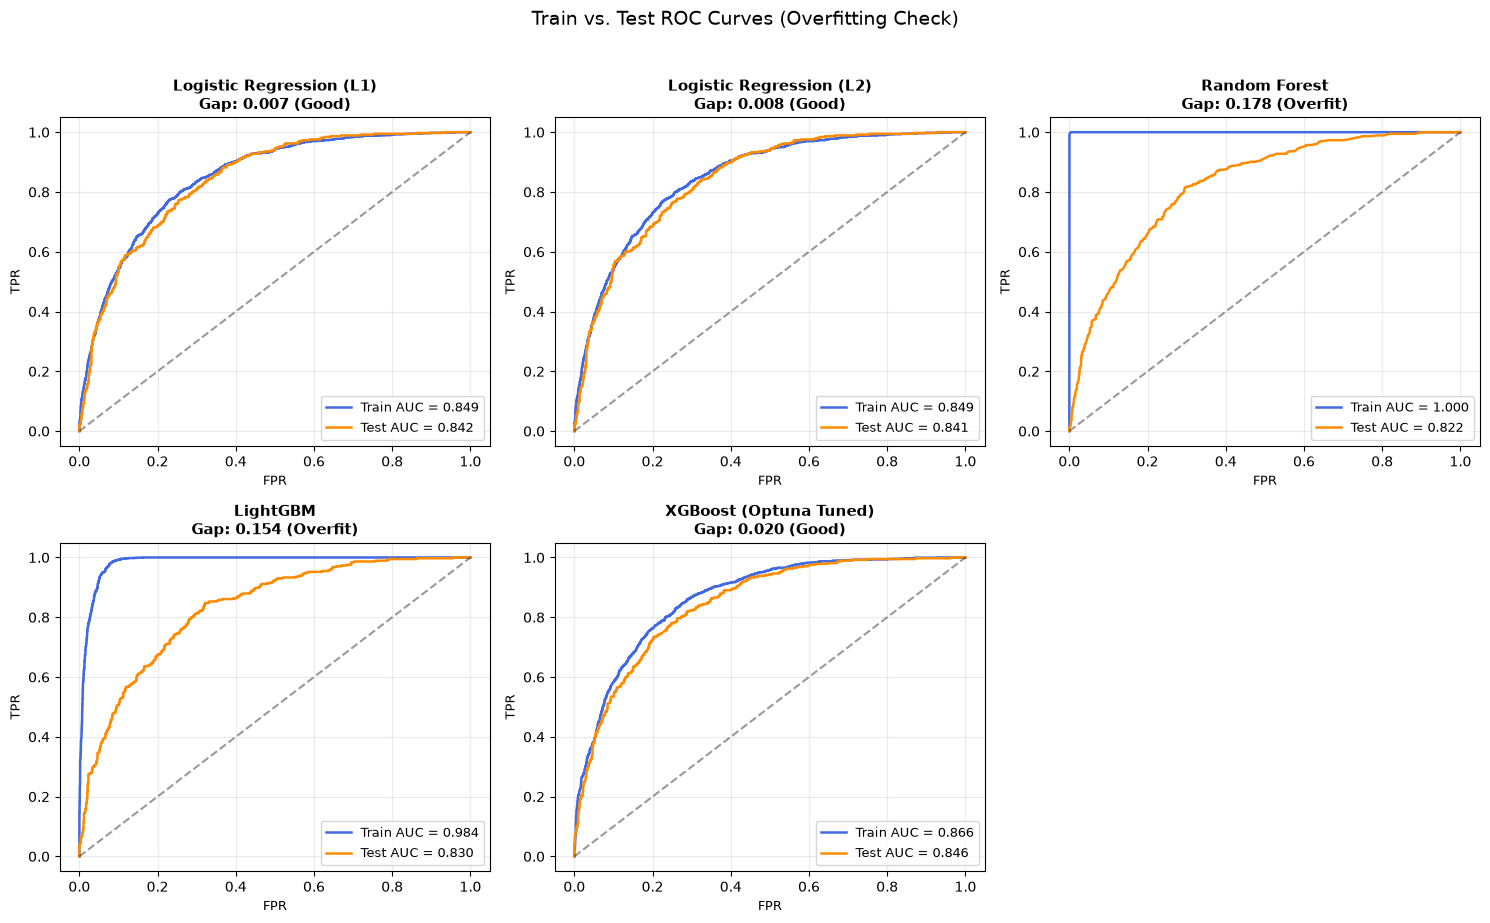


Model Overfitting & Generalization Summary Table:
                   Model  Train ROC-AUC  Test ROC-AUC  Overfitting Gap           Status
  XGBoost (Optuna Tuned)         0.8660        0.8465           0.0195 Well-generalized
Logistic Regression (L1)         0.8490        0.8418           0.0071 Well-generalized
Logistic Regression (L2)         0.8492        0.8414           0.0078 Well-generalized
                LightGBM         0.9842        0.8299           0.1543       Overfitted
           Random Forest         1.0000        0.8216           0.1783       Overfitted


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline

print("=" * 65)
print("Evaluating Generalization & Overfitting Across All 5 Models")
print("=" * 65)

# Dictionary of candidate models
evaluation_models = {
    "Logistic Regression (L1)": models["Logistic Regression (L1/Lasso)"],
    "Logistic Regression (L2)": models["Logistic Regression (L2/Ridge)"],
    "Random Forest": models["Random Forest"],
    "LightGBM": models["LightGBM"],
    "XGBoost (Optuna Tuned)": final_pipeline.named_steps['classifier']
}

results = []

# Create a clean 2x3 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, (name, clf) in enumerate(evaluation_models.items()):
    ax = axes[idx]
    
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    
    # Probabilities
    train_probs = pipe.predict_proba(X_train)[:, 1]
    test_probs = pipe.predict_proba(X_test)[:, 1]
    
    # AUC scores
    train_auc = roc_auc_score(y_train, train_probs)
    test_auc = roc_auc_score(y_test, test_probs)
    gap = train_auc - test_auc
    
    results.append({
        "Model": name,
        "Train ROC-AUC": round(train_auc, 4),
        "Test ROC-AUC": round(test_auc, 4),
        "Overfitting Gap": round(gap, 4),
        "Status": "Overfitted" if gap > 0.05 else "Well-generalized"
    })
    
    # Compute ROC curves for Train and Test
    fpr_tr, tpr_tr, _ = roc_curve(y_train, train_probs)
    fpr_te, tpr_te, _ = roc_curve(y_test, test_probs)
    
    # Plot individual model curve
    ax.plot(fpr_tr, tpr_tr, label=f"Train AUC = {train_auc:.3f}", color='royalblue', linewidth=1.8)
    ax.plot(fpr_te, tpr_te, label=f"Test AUC = {test_auc:.3f}", color='darkorange', linewidth=1.8)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    
    status_label = "Overfit" if gap > 0.05 else "Good"
    ax.set_title(f"{name}\nGap: {gap:.3f} ({status_label})", fontsize=11, fontweight='bold')
    ax.set_xlabel("FPR", fontsize=9)
    ax.set_ylabel("TPR", fontsize=9)
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.25)

# Hide the unused 6th subplot
fig.delaxes(axes[5])

plt.suptitle("Train vs. Test ROC Curves (Overfitting Check)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Display summary table below the plots
auc_summary_df = pd.DataFrame(results).sort_values(by="Test ROC-AUC", ascending=False)
print("\nModel Overfitting & Generalization Summary Table:")
print(auc_summary_df.to_string(index=False))

## Final Model Comparison & Production Selection

| Model | Baseline Recall (0.30) | Final Recall (0.30) | Test ROC-AUC | Overfitting Gap (Train - Test) | Status |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **XGBoost (Optuna Tuned)** | 0.802 | **0.925** | **0.8475** | **0.0169** | Well-generalized |
| **Logistic Regression (L1)** | 0.928 | 0.928 | 0.8418 | 0.0071 | Well-generalized |
| **Logistic Regression (L2)** | 0.928 | 0.928 | 0.8414 | 0.0078 | Well-generalized |
| **LightGBM** | 0.818 | — | 0.8299 | 0.1543 | Overfitted |
| **Random Forest** | 0.842 | — | 0.8216 | 0.1783 | Overfitted |

### Summary & Decision

- **Baseline Overfitting**: Random Forest and LightGBM overfit significantly ($\text{Gap} > 0.15$), heavily memorizing the training split.
- **Regularization Impact**: Constraining tree depth (`max_depth=3`) and applying L1/L2 penalties (`gamma`, `reg_alpha`, `reg_lambda`) via Optuna allowed **XGBoost** to achieve the highest **Test ROC-AUC (0.8475)** and robust **Recall (0.925)** with an overfitting gap of just **0.0169**.

## 7. Model Interpretability: Feature Importance

To understand the key business drivers behind churn predictions, we extract and rank the relative feature importances from our tuned XGBoost model.

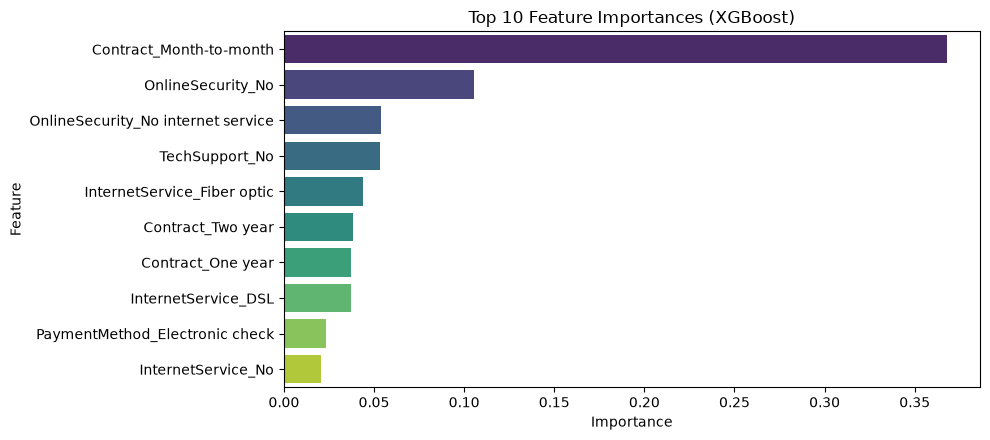

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Extract model and preprocessor
model = final_pipeline.named_steps['classifier']
prep = final_pipeline.named_steps['preprocessor']

cat_features = prep.named_transformers_['cat']['ohe'].get_feature_names_out(categorical_features)
all_features = numeric_features + list(cat_features)

feat_imp_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 4.5))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Feature Importances (XGBoost)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Model Export & MLflow Tracking

In [ ]:
import os
import joblib
import mlflow
from pathlib import Path
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Explicitly allow local file store on Windows
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Define cross-platform directories
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
mlruns_dir = project_root / "mlruns"
mlruns_dir.mkdir(parents=True, exist_ok=True)

# 1. First, save the physical artifact for FastAPI
models_dir = project_root / "src" / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "xgb_pipeline.pkl"
joblib.dump(final_pipeline, str(model_path))

# --- Calculation of metrics for MLflow ---
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
auc = roc_auc_score(y_test, proba)

# 2. Log run, metrics, and artifact to MLflow instantly
mlflow.set_tracking_uri(mlruns_dir.as_uri())
mlflow.set_experiment("Telco_Churn_Production_Pipeline")

with mlflow.start_run():
    # Parameters and threshold
    mlflow.log_params(best_params)
    mlflow.log_param("threshold", THRESHOLD)
    mlflow.log_metric("train_time", train_time)
    mlflow.log_metric("pred_time", pred_time)
    
    # Metrics
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1", f1)
    mlflow.log_metric("roc_auc", auc)
    
    # Log the saved pipeline artifact directly without env-scanning freeze
    mlflow.log_artifact(str(model_path), artifact_path="model")
    
    print("Experiment and parameters successfully logged to MLflow!")
    print(f"Artifact saved to: {model_path}")

Experiment and parameters successfully logged to MLflow!
Artifact saved to: c:\Users\admin\Desktop\Telco Customer Churn ML\src\models\xgb_pipeline.pkl
